# 03 — Model comparison: is the transformer really better?

The fine-tuned `legal-bert-base-uncased` beat the TF-IDF baseline by ~1.5 macro-F1 points on test. But the test set is small (7–38 examples per category), so we check whether that gap is **real or noise** in two ways:

1. **Seeds:** retrain the transformer with 3 random seeds → how much does the score move just from random initialization / data order?
2. **Paired bootstrap:** resample the test set 1,000 times and compare both models on the *same* resample → how often does the transformer actually win?

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

from clausula.data import load_splits
from clausula.labels import LABELS

MODELS = Path("../models")
test = load_splits()["test"]
y_test = test[LABELS].values

/home/davig/clausula/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. All runs

In [2]:
runs = pd.DataFrame([json.loads(p.read_text()) for p in sorted(MODELS.glob("*/results.json"))])
runs[["model", "macro_f1", "micro_f1", "unfair_f1", "ms_per_sentence"]].sort_values("macro_f1", ascending=False)

,model,macro_f1,micro_f1,unfair_f1,ms_per_sentence
3,legal-bert-seed1,0.789,0.781,0.835,3.217
2,legal-bert-base-uncased,0.780,0.775,0.817,3.433
0,distilroberta-10ep,0.778,0.756,0.804,1.475
4,legal-bert-seed2,0.778,0.771,0.820,2.786
1,distilroberta-base,0.721,0.723,0.791,1.447


## 2. Seed variance (legal-bert)

In [3]:
seed_runs = runs[runs["model"].str.startswith("legal-bert")]
display(seed_runs[["model", "macro_f1", "micro_f1", "unfair_f1"]])
seed_runs[["macro_f1", "micro_f1", "unfair_f1"]].agg(["mean", "std"]).round(3)

,model,macro_f1,micro_f1,unfair_f1
2,legal-bert-base-uncased,0.780,0.775,0.817
3,legal-bert-seed1,0.789,0.781,0.835
4,legal-bert-seed2,0.778,0.771,0.820


,macro_f1,micro_f1,unfair_f1
mean,0.782,0.776,0.824
std,0.006,0.005,0.010


## 3. Paired bootstrap: legal-bert (seed 42) vs. baseline

observed difference: +0.014
95% CI of the difference: [-0.045, +0.075]
legal-bert wins in 69% of resamples


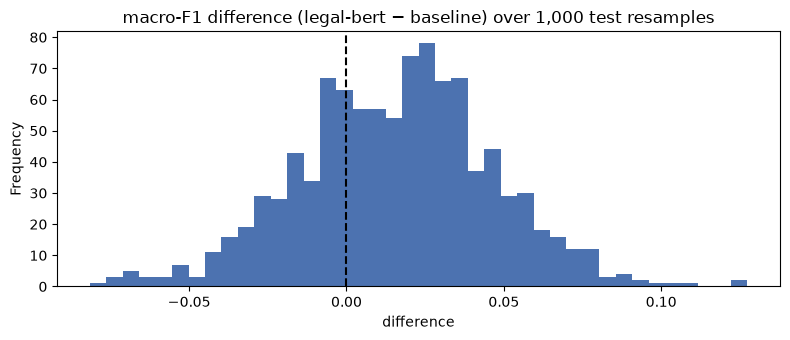

In [4]:
baseline = joblib.load(MODELS / "baseline.joblib")
pred_baseline = baseline["model"].predict_proba(test["text"]) >= baseline["thresholds"]

bert_dir = MODELS / "legal-bert-base-uncased"
pred_bert = np.load(bert_dir / "test_probs.npy") >= np.load(bert_dir / "thresholds.npy")

def macro_f1(y, p):
    return f1_score(y, p, average="macro", zero_division=0)

rng = np.random.default_rng(42)
diffs = []
for _ in range(1000):
    idx = rng.integers(0, len(test), len(test))
    diffs.append(macro_f1(y_test[idx], pred_bert[idx]) - macro_f1(y_test[idx], pred_baseline[idx]))
diffs = np.array(diffs)

low, high = np.percentile(diffs, [2.5, 97.5])
print(f"observed difference: {macro_f1(y_test, pred_bert) - macro_f1(y_test, pred_baseline):+.3f}")
print(f"95% CI of the difference: [{low:+.3f}, {high:+.3f}]")
print(f"legal-bert wins in {(diffs > 0).mean():.0%} of resamples")

ax = pd.Series(diffs).plot.hist(bins=40, figsize=(8, 3.5), color="#4C72B0")
ax.axvline(0, color="black", linestyle="--")
ax.set_title("macro-F1 difference (legal-bert − baseline) over 1,000 test resamples")
ax.set_xlabel("difference")
plt.tight_layout()
plt.show()

## 4. Where does each model win?

In [5]:
per_cat = pd.DataFrame({
    "baseline": f1_score(y_test, pred_baseline, average=None, zero_division=0),
    "legal-bert": f1_score(y_test, pred_bert, average=None, zero_division=0),
    "support": y_test.sum(axis=0),
}, index=LABELS)
per_cat["diff"] = per_cat["legal-bert"] - per_cat["baseline"]
per_cat.round(2).sort_values("diff")

,baseline,legal-bert,support,diff
Arbitration,0.83,0.60,7,-0.23
Contract by using,0.84,0.79,23,-0.05
Unilateral termination,0.70,0.74,38,0.03
Unilateral change,0.68,0.72,38,0.04
Choice of law,0.89,0.93,13,0.04
Limitation of liability,0.72,0.79,38,0.07
Content removal,0.67,0.74,13,0.07
Jurisdiction,0.80,0.94,16,0.14


In [6]:
both = pd.DataFrame({"text": test["text"], "baseline": pred_baseline.any(axis=1), "bert": pred_bert.any(axis=1), "true": y_test.any(axis=1)})
pd.set_option("display.max_colwidth", 200)
print("Unfair clauses only legal-bert caught:")
display(both[both.true & both.bert & ~both.baseline][["text"]].head(5))
print("Unfair clauses only the baseline caught:")
display(both[both.true & both.baseline & ~both.bert][["text"]].head(5))

Unfair clauses only legal-bert caught:


,text
449,"while we 're not required to do so , we may access , review , screen , and delete your content at any time and for any reason , including if we think your content violates these terms ."
478,"and if snap group limited becomes aware that one of its users has repeatedly infringed copyrights , we will take reasonable steps within our power to terminate the user 's account ."
544,"snap group limited may also terminate these terms with you at any time , for any reason ."
912,"in no event will duolingo be responsible for the actions or inactions of any third party payment processor , including , but not limited to , system downtime or payment service outages ."
913,"in the event that duolingo suspends or terminates your use of the service or these terms and conditions or you close your account voluntarily , you understand and agree that you will receive no re..."


Unfair clauses only the baseline caught:


,text
236,amazon has the right but not the obligation to monitor and edit or remove any activity or content .
581,by using the services you agree to be bound by these terms .
585,"you understand that through your use of the services you consent to the collection and use ( as set forth in the privacy policy ) of this information , including the transfer of this information t..."
612,we also retain the right to create limits on use and storage at our sole discretion at any time .
616,we also retain the right to create limits on use and storage at our sole discretion at any time .


## Conclusions

| Model | macro-F1 (test) | ms/sentence | hardware |
|---|---|---|---|
| TF-IDF + LogReg | 0.765 | ~0.04 | CPU |
| distilroberta-base (10 epochs) | 0.778 | ~1.5 | GPU |
| **legal-bert-base-uncased** (3 seeds) | **0.782 ± 0.006** | ~3 | GPU |

1. **The transformer result is stable across seeds** (0.778–0.789, std 0.006), and all 3 seeds beat the baseline. Random initialization is *not* what drives the gap.
2. **But the gap is not statistically significant on this test set.** The paired bootstrap 95% CI of the difference is **[−0.045, +0.075]** and includes zero; legal-bert wins in 69% of resamples. With 7–38 examples per category, the test set is too small to separate two models ~1.5 points apart.
3. **The models are complementary:** legal-bert wins where meaning matters more than keywords — *Jurisdiction* (+0.14), *Limitation of liability* and *Content removal* (+0.07), e.g. *"snap group limited may also terminate these terms with you at any time, for any reason"*. The baseline wins on rigid formulas — *Contract by using* (*"by using the services you agree to be bound…"*) and *Arbitration* (only 7 test examples).
4. **Trade-off:** legal-bert is ~80× slower and benefits from a GPU for a ~1.5 point, not-yet-significant gain.

**Decision for the product:** use **legal-bert** (consistently better, catches paraphrased clauses that matter to users), and keep the baseline as a fast fallback. A promising next experiment is an **ensemble** (average both models' probabilities), since their errors differ.
